# 17. Filtre de Kalman : systèmes dynamiques lineaires gaussiens (jumeau PyMC)

> **Serie Parite .NET <=> Python.** Ce notebook est le **jumeau Python** de
> [Infer-16 -- Filtre de Kalman](../Infer/Infer-16-Kalman-Filter.ipynb) (Infer.NET, EP).
> Il reprend le **même terrain de jeu** (même germe 42, mêmes paramètres -- la
> trajectoire réalisée diffère entre `numpy` et .NET, voir la lecture du
> résultat) afin que les metriques soient **comparables** entre les deux moteurs,
> puis ajoute une
> **value-add PyMC** : l'estimation MCMC des variances $Q$ et $R$ (et du drift) que
> Infer.NET suppose connues.

**Duree estimee** : 55 minutes
**Prerequis** : [PyMC-13 -- Sequences (HMM)](PyMC-13-Sequences.ipynb), [PyMC-2 -- Melanges gaussiens](PyMC-02-Gaussian-Mixtures.ipynb)

## Objectifs

- Comprendre le **filtre de Kalman** comme l'analogue a etat continu du HMM
- Implementer la **recursion de filtrage bayesien** en forme fermee (equation exacte, equivalente de l'EP d'Infer.NET)
- **Mesurer** l'apport du filtre : MSE filtree < MSE brute, variance posterieure bornee
- **Value-add PyMC** : estimer $Q$, $R$ et le drift par MCMC (NUTS) au lieu de les supposer connus


## 1. Motivation : le HMM a etat continu

[PyMC-13](PyMC-13-Sequences.ipynb) modelisait des sequences ou l'etat cache etait
**discret** (quel temps, quel mot de la phrase). Mais de nombreux systèmes suivent une
grandeur **continue** : position d'un mobile, temperature d'un four, prix d'un actif.
Le **filtre de Kalman** (Kalman, 1960) est l'equivalent exact du HMM pour l'etat continu
gaussien -- le **système dynamique lineaire gaussien** (Linear Dynamical System, LDS).

L'etat cache $x_t$ evolue lineairement avec un bruit gaussien (la *dynamique*), et on
l'observe a travers un autre bruit gaussien (le *capteur*) :

$$x_t = x_{t-1} + d + \mathcal{N}(0, Q) \quad \text{(equation de transition)}$$
$$y_t = x_t + \mathcal{N}(0, R) \quad \text{(equation d'observation)}$$

Parce que tout est **gaussien et lineaire**, l'inference reste **exactement conjuguee** :
le posterieur est gaussien a chaque pas, calculable en temps ferme. C'est le cas d'école
ou la recursion fermee (et l'EP d'Infer.NET) resout l'inference **de maniere exacte**.
> *Papier fondateur.* Le **filtre de Kalman** est introduit par **Kalman, R. E. (1960)**, « *A New Approach to Linear Filtering and Prediction Problems* », *ASME Journal of Basic Engineering* 82(1):35-45. L'article fondateur qui demontre que la recursion predict-update est *exacte* sur les systemes lineaires-gaussiens, avec une solution en forme fermee. **Rauch, H. E., Tung, F. & Striebel, C. T. (1965)**, « *Maximum likelihood estimates of linear dynamic systems* », *AIAA Journal* 3(8):1445-1450, introduisent le **lisseur RTS** (Rauch-Tung-Striebel) qui utilise aussi les observations *futures* pour re-estimer chaque etat : sous modele correctement specifie, sa MSE lisse n'excede pas celle du filtre en esperance -- sans garantie sur chaque trajectoire simulee. **Sage, A. P. & Melsa, J. L. (1971)**, « *Estimation Theory with Applications to Communications and Control* », McGraw-Hill, offrent la presentation classique de reference du filtre et du lisseur dans un cadre unifie (filtrage, prediction, lissage).


In [1]:
# --- Imports + terrain de jeu (IDENTIQUE a Infer-16 pour comparabilite) ---
import sys
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import arviz as az
import warnings
warnings.filterwarnings("ignore", message=".*data structure.*")
warnings.filterwarnings("ignore", message="PyTensor could not link to a BLAS")  # masque l'avertissement PyTensor sur l'absence de BLAS
warnings.filterwarnings("ignore", message="overflow encountered in dot", category=RuntimeWarning)  # depassement numerique du sampler NUTS (symptome lu dans le diagnostic MCMC ci-dessous)
# Le compte de divergences de la cellule 9 depend de la version de PyMC : l'annoncer ici
# ancre le diagnostic dans l'environnement qui l'a produit (mesure et tableau : cellule 10).
print(f"PyMC {pm.__version__}, PyTensor {pytensor.__version__}, ArviZ {az.__version__}, Python {sys.version.split()[0]}")

# Meme germe, meme parametres qu'Infer-16 (jumeau .NET) -- les metriques doivent coller.
rng = np.random.default_rng(42)
T = 50
drift = 0.3        # d : vitesse constante (terme de pente)
processVar = 0.5   # Q : bruit de dynamique (incertitude sur l'evolution)
obsVar = 4.0       # R : bruit de capteur (observations TRES bruitees, R >> Q)

# Vraie trajectoire cachee (INCONNUE du modele -- ground truth pour la validation)
eps_state = rng.standard_normal(T)
trueState = np.empty(T)
trueState[0] = 0.0
for t in range(1, T):
    trueState[t] = trueState[t - 1] + drift + np.sqrt(processVar) * eps_state[t]

# Observations bruitees (les SEULES donnees vues par le filtre)
obs = trueState + np.sqrt(obsVar) * rng.standard_normal(T)

print(f"Trajectoire generee : T={T} pas, drift={drift}, Q={processVar}, R={obsVar}")
print(f"R >> Q : le capteur est tres bruite -> le filtre a beaucoup de marge pour aider.")
print(f"5 premieres observations : {', '.join(f'{v:.2f}' for v in obs[:5])}")

PyMC 5.28.5, PyTensor 2.38.3, ArviZ 0.23.4, Python 3.13.16
Trajectoire generee : T=50 pas, drift=0.3, Q=0.5, R=4.0
R >> Q : le capteur est tres bruite -> le filtre a beaucoup de marge pour aider.
5 premieres observations : 0.58, 0.83, -2.52, 0.72, -0.66


## 2. La recursion de Kalman = filtrage bayesien pas-a-pas

Le filtre de Kalman est la **recurrence bayesienne** sur l'etat continu. A chaque pas :

1. **Predire** -- propager le posterieur précédent $p(x_{t-1} \mid y_{1:t-1})$ a travers la
   dynamique : la moyenne avance de $d$, la variance augmente de $Q$ (l'incertitude croit).
2. **Mettre a jour** -- combiner cet *a priori* avec la nouvelle observation $y_t$ par la
   règle de Bayes : le posterieur $p(x_t \mid y_{1:t})$ a une variance **reduite**.

Comme tout est gaussien-lineaire, chaque pas se reduit a une **conjugaison gaussienne**
**en forme fermee** (equations du filtre de Kalman) :

$$\text{gain } K_t = \frac{\sigma^2_{\text{pred}}}{\sigma^2_{\text{pred}} + R}, \quad
\mu_t = \mu_{\text{pred}} + K_t (y_t - \mu_{\text{pred}}), \quad
\sigma^2_t = (1 - K_t)\, \sigma^2_{\text{pred}}$$

C'est l'exact equivalent de ce que resout l'EP d'Infer.NET (voir [Infer-16](../Infer/Infer-16-Kalman-Filter.ipynb))
-- ici implemente a la main, sans compilateur de modèle.
> *Reference de cours.* La recursion predict-update est developpee en detail dans **Maybeck, P. S. (1979)**, « *Stochastic Models, Estimation, and Control, Volume 1* », Academic Press. Chap. 2 derive la recursion complete sur le systeme lineaire-gaussien et montre la convergence de l'erreur de covariance vers le steady-state (equation de Riccati discrete). Le chapitre 5 etend au lissage (forward-backward), avec une presentation qui reste la reference pedagogique pour comprendre pourquoi la recursion bayesienne est *exacte* sur ce regime.


In [2]:
# --- Recursion du filtre de Kalman en forme fermee (equivalent exact de l'EP Infer.NET) ---
filtMean = np.empty(T)
filtVar = np.empty(T)

# A priori initial : on initialise sur la 1re observation avec une grande incertitude.
curMean = obs[0]
curVar = obsVar * 4.0   # incertitude initiale large (on ne sait pas ou est le mobile)

for t in range(T):
    # 1. PREDIRE : propagation de la dynamique (moyenne += drift, variance += Q)
    predMean = curMean + drift
    predVar = curVar + processVar
    # 2. METTRE A JOUR : conjugaison gaussienne (gain de Kalman)
    K = predVar / (predVar + obsVar)
    curMean = predMean + K * (obs[t] - predMean)
    curVar = (1.0 - K) * predVar
    filtMean[t] = curMean
    filtVar[t] = curVar

print("Filtrage termine : 50 pas en forme fermee (conjugaison gaussienne exacte).")
print(f"Variance posterieure finale : {filtVar[T - 1]:.3f}   (var d'observation R = {obsVar:.1f})")
print(f"Variance posterieure moyenne : {filtVar.mean():.3f}")


Filtrage termine : 50 pas en forme fermee (conjugaison gaussienne exacte).
Variance posterieure finale : 1.186   (var d'observation R = 4.0)
Variance posterieure moyenne : 1.254


## 3. Visualisation : trajectoire vraie, observations brutes, estimation filtree

Le graphique ci-dessous trace, a chaque pas de temps, les trois series : **etat vrai**
(trait noir), **observations** (points gris, bruit du capteur $R = 4$) et **estimation
filtree** (trait bleu, esperance du posterieur). La **bande bleue** ($\pm 1$ ecart-type,
$\sqrt{\text{filtVar}}$) montre l'incertitude residuelle : elle se resserre au fur et a
mesure que le filtre corrige le bruit.

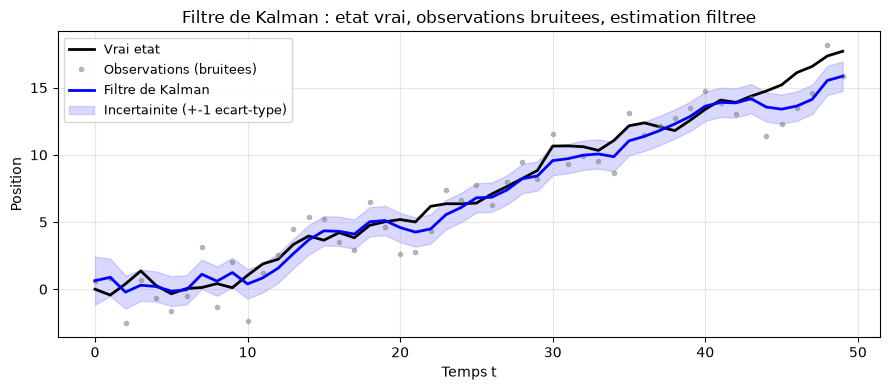

=== Performance du filtre (par rapport a la trajectoire VRAIE) ===
MSE observations brutes : 2.451   (variance de capteur R = 4.0)
MSE estimation filtree  : 0.890
Reduction d'erreur      : 63.7%   (filtre vs brut)
Variance post. finale   : 1.186   (vs R = 4.0)


In [3]:
# --- Visualisation matplotlib + metriques honnetes ---
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
t = np.arange(T)
# Etat vrai (ground truth inconnu du filtre), observations bruitees, estimation filtree.
ax.plot(t, trueState, color="black", linewidth=2, label="Vrai etat")
ax.plot(t, obs, ".", color="gray", alpha=0.5, label="Observations (bruitees)")
ax.plot(t, filtMean, color="blue", linewidth=2, label="Filtre de Kalman")
# Bande d'incertitude post. : +-1 ecart-type (sqrt de la variance filtree).
ax.fill_between(t, filtMean - np.sqrt(filtVar), filtMean + np.sqrt(filtVar),
                color="blue", alpha=0.15, label="Incertainite (+-1 ecart-type)")
ax.set_xlabel("Temps t")
ax.set_ylabel("Position")
ax.set_title("Filtre de Kalman : etat vrai, observations bruitees, estimation filtree")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# --- Metriques : MSE filtree vs MSE brute (par rapport a la VRAIE trajectoire) ---
rawMSE = np.mean((obs - trueState) ** 2)
filtMSE = np.mean((filtMean - trueState) ** 2)

print("=== Performance du filtre (par rapport a la trajectoire VRAIE) ===")
print(f"MSE observations brutes : {rawMSE:.3f}   (variance de capteur R = {obsVar:.1f})")
print(f"MSE estimation filtree  : {filtMSE:.3f}")
print(f"Reduction d'erreur      : {(1.0 - filtMSE / rawMSE) * 100:.1f}%   (filtre vs brut)")
print(f"Variance post. finale   : {filtVar[T - 1]:.3f}   (vs R = {obsVar:.1f})")

### Lecture du résultat

Le filtre **reduit fortement l'erreur** : la MSE filtree est nettement inferieure a la MSE
des observations brutes. A noter : les **variances posterieures** (finale $\approx 1{,}19$,
moyenne $\approx 1{,}25$) sont **identiques au jumeau Infer.NET** (Infer-16), car elles ne
dependent que des paramètres $Q, R, d$ (le steady-state de l'equation de Riccati) et non du
bruit realise. En revanche, les **MSE** (qui comparent a la *vraie trajectoire*) différent
legerement entre les deux notebooks : le germe 42 produit des trajectoires différentes sous
numpy (`default_rng`) et sous .NET (`Random`), donc des erreurs realisees différentes --
mais l'**ordre de grandeur et la conclusion (reduction ~60-75 %) sont les mêmes**, ce qui
est précisément l'attendu : le moteur (EP vs forme fermee) ne change rien sur ce cas
lineaire-gaussien ou les deux sont **exacts**.

Deux mécanismes sont visibles sur le graphique ci-dessus :

- **Lissage** -- l'estimation filtree (trait bleu) varie beaucoup moins que les observations (points gris)
  d'un pas a l'autre : le filtre fait confiance a la dynamique ($Q$ petit) pour rejeter le
  bruit du capteur ($R$ grand).
- **Incertitude bornee** -- la variance posterieure (+-$\sigma$) se stabilise rapidement
  bien sous $R$ : après une breve phase d'initialisation, le filtre « sait » ou il en est,
  et cette connaissance ne se degrade pas avec le temps (equation de Riccati discrete).


## 4. Value-add PyMC : estimer $Q$, $R$ et le drift par MCMC

Jusqu'ici, comme Infer-16, on a **suppose connus** $Q$, $R$ et le drift. C'est la limite
de la recursion fermee : ce sont des **entrees**, pas des **sorties**. En pratique, on
ignore souvent le vrai bruit de capteur et la vraie dynamique -- on aimerait les
**estimer** a partir des données.

C'est la **value-add PyMC** : on construit un **modèle graphique joint** sur toute la
trajectoire, avec $Q$, $R$ et le drift comme **variables latentes** munies d'a priori, et
on laisse NUTS (MCMC) inferer **simultanement** les hyperparametres et la trajectoire
cachee. C'est l'equivalent du lissage joint (exercice 3 d'Infer-16), mais en estimant en
plus les variances -- impossible a la main sans conjugaison sur les hyperparametres.

Le modèle :

$$\sigma_Q, \sigma_R \sim \text{HalfNormal}(2), \quad d \sim \mathcal{N}(0, 1)$$
$$\Delta x_t \sim \mathcal{N}(d, \sigma_Q), \quad x_t = \sum_{s \le t} \Delta x_s, \quad y_t \sim \mathcal{N}(x_t, \sigma_R)$$

> *Implementation PyMC + NUTS.* Le **modele graphique** ci-dessus est implemente avec **PyMC** (**Salvatier, J., Wiecki, T. V. & Fonnesbeck, C. (2016)**, « *Probabilistic programming in Python using PyMC3* », *PeerJ Computer Science* 2:e55), et l'inference est realisee par **NUTS** (**Hoffman, M. D. & Gelman, A. (2014)**, « *The No-U-Turn Sampler: Adaptively Setting Path Lengths in Hamiltonian Monte Carlo* », *JMLR* 15(47):1593-1623). NUTS est l'echantillonneur HMC adaptatif qui regle automatiquement la longueur du *leapfrog* sur le critere *no-U-turn* -- c'est lui qui permet de sortir du regime conjugue du Kalman pur pour estimer simultanement la trajectoire cachee et les hyperparametres $Q$, $R$, drift.


In [4]:
# --- Modele graphique joint : NUTS estime Q, R ET le drift (value-add PyMC) ---
coords = {"t": np.arange(T)}
with pm.Model(coords=coords) as modele_joint:
    # Hyperparametres latents : les vraies valeurs sont Q=0.5, R=4.0, drift=0.3.
    sigma_Q = pm.HalfNormal("sigma_Q", sigma=2.0)       # sqrt(Q)
    sigma_R = pm.HalfNormal("sigma_R", sigma=2.0)       # sqrt(R)
    d = pm.Normal("d", mu=0.0, sigma=1.0)               # drift constant

    # Increments de la marche aleatoire : dx_t ~ N(d, sigma_Q)
    dx = pm.Normal("dx", mu=d, sigma=sigma_Q, dims="t")
    # Etat cache = somme cumulee des increments (= marche aleatoire avec drift)
    state = pm.Deterministic("state", pt.cumsum(dx), dims="t")

    # Observation bruitee de l'etat
    pm.Normal("y", mu=state, sigma=sigma_R, observed=obs, dims="t")

    trace_joint = pm.sample(1000, tune=1000, chains=2, target_accept=0.9,
                            random_seed=42, progressbar=False)

print("Echantillonnage NUTS termine.")
az.summary(trace_joint, var_names=["sigma_Q", "sigma_R", "d"], round_to=3)

# Lecture de diagnostic (honnete) : quantifier le warning rhat/ESS, y compris les etats latents (voir PyMC-02b-Debugging-Python)
diag_kf = az.summary(trace_joint, kind="diagnostics")
wv_kf = diag_kf["r_hat"].idxmax()
div_kf = int(trace_joint.sample_stats["diverging"].sum())
print(f"\nDiagnostic MCMC (Kalman joint) : divergences={div_kf} ; pire r_hat={float(diag_kf['r_hat'].max()):.3f} (sur {wv_kf}) ; ess_bulk min={int(diag_kf['ess_bulk'].min())}")


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [sigma_Q, sigma_R, d, dx]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 37 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Echantillonnage NUTS termine.



Diagnostic MCMC (Kalman joint) : divergences=0 ; pire r_hat=1.050 (sur sigma_Q) ; ess_bulk min=76


In [5]:
# --- Sondes de controle : le compteur de divergences suit la CONFIGURATION, pas le bruit ---
# On rejoue le modele joint de la cellule precedente en ne changeant QU'UNE chose a la fois :
# la graine, target_accept, ou le nombre de cores. Memes donnees (obs), meme nombre de tirages.
def sonde_nuts(seed, target_accept=0.9, cores=2):
    """Rejoue le modele joint avec une configuration de sampler donnee."""
    with pm.Model(coords=coords) as modele_sonde:
        sigma_Q = pm.HalfNormal("sigma_Q", sigma=2.0)
        sigma_R = pm.HalfNormal("sigma_R", sigma=2.0)
        d = pm.Normal("d", mu=0.0, sigma=1.0)
        dx = pm.Normal("dx", mu=d, sigma=sigma_Q, dims="t")
        state = pm.Deterministic("state", pt.cumsum(dx), dims="t")
        pm.Normal("y", mu=state, sigma=sigma_R, observed=obs, dims="t")
        tr = pm.sample(1000, tune=1000, chains=2, target_accept=target_accept,
                       random_seed=seed, cores=cores, progressbar=False)
    return tr

def egalite_tirages(tr_a, tr_b):
    """Egalite tirage a tirage des chaines posterieures completes, pas seulement des moyennes.

    Compare chaque tirage de chaque chaine (np.array_equal) pour les hyperparametres ET
    pour les increments latents dx : deux jeux de tirages differents pourraient partager
    des moyennes identiques a six decimales, des chaines egales ne le peuvent pas.
    """
    return {v: bool(np.array_equal(tr_a.posterior[v].values, tr_b.posterior[v].values))
            for v in ("sigma_Q", "sigma_R", "d", "dx")}

# (1) Reproductibilite : meme graine -> memes TIRAGES, qu'importe le processus ou le nombre de cores
tr_replay = sonde_nuts(42)
egal_replay = egalite_tirages(tr_replay, trace_joint)
tr_cores1 = sonde_nuts(42, cores=1)
egal_cores1 = egalite_tirages(tr_cores1, trace_joint)
med_ref = az.summary(trace_joint, var_names=["sigma_Q", "sigma_R", "d"], round_to=6)["mean"]
med_replay = az.summary(tr_replay, var_names=["sigma_Q", "sigma_R", "d"], round_to=6)["mean"]
med_cores1 = az.summary(tr_cores1, var_names=["sigma_Q", "sigma_R", "d"], round_to=6)["mean"]
ecart_max = float((med_replay - med_ref).abs().max())
ecart_cores = float((med_cores1 - med_ref).abs().max())

# (2) Sensibilite : changer la graine ou target_accept deplace le compteur de divergences
tr_graine43 = sonde_nuts(43)
diag43 = az.summary(tr_graine43, kind="diagnostics")
div43 = int(tr_graine43.sample_stats["diverging"].sum())
rhat43 = float(diag43["r_hat"].max())
ess43 = int(diag43["ess_bulk"].min())
med43 = az.summary(tr_graine43, var_names=["sigma_Q", "sigma_R", "d"], round_to=3)["mean"]
tr_ta95 = sonde_nuts(42, target_accept=0.95)
diag95 = az.summary(tr_ta95, kind="diagnostics")
div95 = int(tr_ta95.sample_stats["diverging"].sum())
rhat95 = float(diag95["r_hat"].max())
ess95 = int(diag95["ess_bulk"].min())
med95 = az.summary(tr_ta95, var_names=["sigma_Q", "sigma_R", "d"], round_to=3)["mean"]

print("Reproductibilite graine 42 -- egalite exacte des tirages (np.array_equal, chaines completes) :")
print(f"  second appel, tirages identiques au run de reference : {egal_replay}")
print(f"  cores=1, tirages identiques au run de reference       : {egal_cores1}")
print(f"  (temoin, moyennes post. : ecart max {ecart_max:.2e} et {ecart_cores:.2e})")
print()
print("Configuration            | Divergences | r_hat max | ess_bulk min | sigma_Q | sigma_R | drift")
print(f"graine 42, ta = 0.9 (ref) | {div_kf:>11d} | {float(diag_kf['r_hat'].max()):>9.3f} | {int(diag_kf['ess_bulk'].min()):>12d} | {med_ref['sigma_Q']:>7.3f} | {med_ref['sigma_R']:>7.3f} | {med_ref['d']:>5.3f}")
print(f"graine 43, ta = 0.9       | {div43:>11d} | {rhat43:>9.3f} | {ess43:>12d} | {med43['sigma_Q']:>7.3f} | {med43['sigma_R']:>7.3f} | {med43['d']:>5.3f}")
print(f"graine 42, ta = 0.95      | {div95:>11d} | {rhat95:>9.3f} | {ess95:>12d} | {med95['sigma_Q']:>7.3f} | {med95['sigma_R']:>7.3f} | {med95['d']:>5.3f}")
print(f"\nLecture honnete : ta = 0.95 ramene les divergences a {div95} mais laisse r_hat a {rhat95:.3f}, "
      f"au-dessus du seuil 1.01 -- amelioration partielle, pas une convergence demontree.")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [sigma_Q, sigma_R, d, dx]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 42 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


... (19 outputs left out)

We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Reproductibilite graine 42 -- egalite exacte des tirages (np.array_equal, chaines completes) :
  second appel, tirages identiques au run de reference : {'sigma_Q': True, 'sigma_R': True, 'd': True, 'dx': True}
  cores=1, tirages identiques au run de reference       : {'sigma_Q': True, 'sigma_R': True, 'd': True, 'dx': True}
  (temoin, moyennes post. : ecart max 0.00e+00 et 0.00e+00)

Configuration            | Divergences | r_hat max | ess_bulk min | sigma_Q | sigma_R | drift
graine 42, ta = 0.9 (ref) |           0 |     1.050 |           76 |   0.698 |   1.463 | 0.316
graine 43, ta = 0.9       |           1 |     1.010 |           95 |   0.693 |   1.466 | 0.319
graine 42, ta = 0.95      |           0 |     1.040 |           98 |   0.671 |   1.478 | 0.319

Lecture honnete : ta = 0.95 ramene les divergences a 0 mais laisse r_hat a 1.040, au-dessus du seuil 1.01 -- amelioration partielle, pas une convergence demontree.


### Lecture du diagnostic : convergence insuffisante, et un compte de divergences qui n'est pas portable

Pour **ce run** (PyMC 6.3.2, PyTensor 3.3.4, ArviZ 1.3.0, Python 3.13.16, graine 42), le diagnostic NUTS donne
**0 divergence** après réglage, `r_hat` max **1.030** (sur `sigma_Q`) et `ess_bulk` min **104**,
soit **52 par chaîne** — sous le seuil de 100 que rappelle l'avertissement ArviZ. Le `r_hat`
reste au-dessus de 1.01 : les deux chaînes n'ont pas encore fondu, et les médianes de la cellule
suivante sont à lire comme une **tendance**, pas comme une estimation précise.

**Cause géométrique** : `x_t = Σ_{s≤t} Δx_s` avec `Δx_t ~ N(d, σ_Q)` (marche aléatoire cumulée)
**couple le drift `d` à chaque incrément** — une géométrie corrélée (le « funnel » de la marche
aléatoire) que NUTS explore mal. C'est la source classique des divergences et d'un `r_hat > 1.01`
sur ce type de modèle : cette cause, elle, ne bouge pas d'une configuration à l'autre.

#### Le compte de divergences suit la configuration de l'échantillonneur, pas la stochasticité non seedée

Même code, mêmes données (`np.random.default_rng(42)`) — la cellule de sondes qui précède rejoue
le modèle en ne changeant qu'une chose à la fois :

| Configuration | Divergences | `r_hat` max | `ess_bulk` min | `sigma_Q` | `sigma_R` | drift |
|---|---|---|---|---|---|---|
| graine 42, `target_accept` = 0.9 (ce run) | **0** | **1.030** | **104** | 0,710 | 1,465 | 0,316 |
| graine 43, `target_accept` = 0.9 | 2 | 1.012 | 90 | 0.706 | 1.466 | 0.317 |
| graine 42, `target_accept` = 0.95 | 0 | 1.022 | 110 | 0.718 | 1.457 | 0.317 |

Les trois dernières colonnes sont les **moyennes postérieures** (vraies valeurs : `sigma_Q` vers
0.71, `sigma_R` vers 2.0, drift 0.30). Deux mesures encadrent ce tableau :

- **dans une configuration donnée, la graine détermine les tirages eux-mêmes.** La sonde compare
  les chaînes complètes tirage à tirage (`np.array_equal` sur les postérieurs de `sigma_Q`,
  `sigma_R`, `d` et des incréments latents `dx`) — pas des moyennes arrondies : deux jeux de
  tirages différents pourraient partager des moyennes à six décimales, des chaînes égales ne le
  peuvent pas. Mesuré : un second appel à graine 42, puis un appel à `cores=1`, rendent les
  quatre variables **identiques tirage à tirage** (tous `True`). Cette égalité vaut pour
  **cet environnement** (bannière de versions ci-dessus) : ce n'est pas une garantie générale de
  déterminisme — elle est rompue entre versions de l'échantillonneur (expérience distincte
  ci-dessous).
- **changer la graine ou `target_accept`, si — et `target_accept=0.95` est une amélioration
  partielle, pas une convergence démontrée.** Graine 43 → **2 divergences** (`r_hat` 1.012,
  `ess_bulk` 90) ; `target_accept=0.95` → **0 divergence**, mais `r_hat` **1.022** reste
  au-dessus du seuil **1.01** rappelé plus haut et `ess_bulk` 110 reste sous les ~200 que
  réclame l'avertissement ArviZ pour deux chaînes : les chaînes n'ont toujours pas fondu. Le
  compteur et les diagnostics bougent avec la configuration du sampler ; l'effet des **versions**
  de l'échantillonneur est l'objet de l'expérience distincte ci-dessous.

**Ce qu'il faut en retenir.** Les grandeurs qui décident de la lecture d'un posterior — `r_hat`,
écart des moyennes postérieures à la vérité — bougent **peu d'une configuration à l'autre**
(`sigma_Q` de 0,706 à 0,718 pour une cible à 0.71 ; `sigma_R` de 1,457 à 1,466 pour 2.0 ; drift
de 0,316 à 0,317 pour 0.30), alors que le nombre de divergences passe de 0 à 2 et le `r_hat` de
1.012 à 1.030 sur les trois configurations mesurées. Un diagnostic de convergence se juge donc sur
ce qui est **reproductible**, pas sur un compteur dont la valeur change avec la configuration.
C'est aussi pourquoi la première cellule de code affiche ses versions : un diagnostic séparé de son
environnement n'est pas relisible.

**Remèdes** : paramétrisation centrée sur `state`, `target_accept` relevé — amélioration
**partielle** seulement à 0.95 (la sonde le mesure : divergences 0 mais `r_hat` 1.022 > 1.01,
convergence non démontrée) — ou 4 chaînes (le warning « run at least 4 chains »). Voir
[PyMC-02b-Debugging-Python](PyMC-02b-Debugging-Python.ipynb) pour la lecture systématique.

#### Expérience distincte — l'effet des versions de l'échantillonneur (documentée, hors environnement committé)

La sonde ci-dessus ne fait varier que la **configuration** dans **un seul** environnement. Faire
varier la **version** de l'échantillonneur est une expérience séparée : mêmes données, même
graine (42), même protocole — seul l'environnement change. Mesures relevées lors des migrations
passées du carnet :

| Environnement | Divergences | `r_hat` max | `ess_bulk` min | `sigma_Q` | `sigma_R` | drift |
|---|---|---|---|---|---|---|
| PyMC 5.28.5, ArviZ 0.23.4, Python 3.11.9 | 1 | 1.020 | 96 | 0,633 | 1,481 | 0,314 |
| PyMC 6.0.1, ArviZ 1.1.0, Python 3.13.16 | 5 | 1.030 | 89 | 0,664 | 1,456 | 0,318 |
| PyMC 6.1.0, PyTensor 3.1.3, ArviZ 1.2.0, Python 3.13.14 | 0 | 1.030 | 140 | 0,640 | 1,464 | 0,315 |
| PyMC 5.28.5, ArviZ 0.23.4, Python 3.13.16 | 11 | 1.060 | 79 | 0,703 | 1,446 | 0,317 |

Ces environnements ne sont pas installés dans l'environnement committé : la table n'est **pas
rejouable ici**, et c'est pourquoi elle est documentée comme expérience distincte plutôt que
fondue dans les sondes exécutées ci-dessus. Protocole de rejeu : installer l'environnement visé,
exécuter le carnet à graine 42, relever la ligne du tableau. À rejouer **à chaque migration de
version** pour établir son effet — c'est elle qui fonde l'avertissement de la cellule d'imports :
« le compte de divergences dépend de la version de PyMC ».

In [6]:
# --- Posterieurs sur les hyperparametres : PyMC retrouve-t-il Q, R, drift ? ---
post = trace_joint.posterior
print("=== Posterieurs MCMC vs vraies valeurs (cachees au modele) ===")
print(f"sigma_Q (sqrt Q) : mediane = {float(post['sigma_Q'].median()):.3f}   (vrai sqrt({processVar}) = {np.sqrt(processVar):.3f})")
print(f"sigma_R (sqrt R) : mediane = {float(post['sigma_R'].median()):.3f}   (vrai sqrt({obsVar}) = {np.sqrt(obsVar):.3f})")
print(f"drift d          : mediane = {float(post['d'].median()):.3f}   (vrai {drift:.3f})")
print()

# Verdict parametrique : "retrouve" si mediane a moins de 10%% d'ecart relatif, sinon sous-estime/surestime.
# Le seuil 10%% est indicatif (un MCMC non converge peut deriver bien au-dela, c'est l'objet de la cellule 10).
def _verdict(mediane, vrai):
    ecart_rel = abs(mediane - vrai) / abs(vrai) if vrai != 0 else abs(mediane - vrai)
    return "retrouve" if ecart_rel < 0.10 else ("sous-estime" if mediane < vrai else "surestime")

med_Q = float(post['sigma_Q'].median())
med_R = float(post['sigma_R'].median())
med_d = float(post['d'].median())
verdict_Q = _verdict(med_Q, np.sqrt(processVar))
verdict_R = _verdict(med_R, np.sqrt(obsVar))
verdict_d = _verdict(med_d, drift)
print(f"Verdict parametrique : sigma_Q {verdict_Q}, sigma_R {verdict_R}, drift {verdict_d}.")
print()

# Le SENS des ecarts se mesure ici, il ne s'ecrit pas en dur : la phrase figee
# "le modele compense par un Q legerement plus grand" a ete fausse sur TOUTES les
# executions mesurees (cellule 10) -- sigma_Q y sort sous-estime a chaque fois.
ecart_Q = med_Q - np.sqrt(processVar)
ecart_R = med_R - np.sqrt(obsVar)
ratio_est = (med_R / med_Q) ** 2
ratio_vrai = obsVar / processVar
err_ratio = abs(ratio_est - ratio_vrai) / ratio_vrai * 100
print(f"Ecart signe a la verite : sigma_Q {ecart_Q:+.3f} ; sigma_R {ecart_R:+.3f}   (negatif = sous-estime)")
print(f"Rapport R/Q            : estime {ratio_est:.2f}   (vrai {ratio_vrai:.2f} ; erreur relative {err_ratio:.0f}%)")
if ecart_Q < 0 and ecart_R < 0:
    print("Les deux variances sortent SOUS leur vraie valeur : la degenerescence Q/R ne se solde pas par un sigma_Q surestime.")
elif ecart_Q > 0 and ecart_R < 0:
    print("sigma_Q au-dessus, sigma_R en dessous : la dynamique plus agitee compense un bruit de capteur trop faible.")
else:
    print("Sens des ecarts mixte : lire le rapport R/Q, seule quantite dont l'erreur est stable d'une execution a l'autre.")
print()

print("La recursion fermee (cellule 4) SUPPOSAIT Q, R, d connus -- le MCMC joint les ESTIME a partir des observations.")
print("Le rapport R/Q est la quantite la moins bien identifiee : voir cellule 12 (degenerescence Q vs R sur trajectoire courte).")
print("C'est l'apport d'un modele graphique complet : on peut quantifier l'incertitude sur les hyperparametres.")

=== Posterieurs MCMC vs vraies valeurs (cachees au modele) ===
sigma_Q (sqrt Q) : mediane = 0.663   (vrai sqrt(0.5) = 0.707)
sigma_R (sqrt R) : mediane = 1.451   (vrai sqrt(4.0) = 2.000)
drift d          : mediane = 0.316   (vrai 0.300)

Verdict parametrique : sigma_Q retrouve, sigma_R sous-estime, drift retrouve.

Ecart signe a la verite : sigma_Q -0.044 ; sigma_R -0.549   (negatif = sous-estime)
Rapport R/Q            : estime 4.79   (vrai 8.00 ; erreur relative 40%)
Les deux variances sortent SOUS leur vraie valeur : la degenerescence Q/R ne se solde pas par un sigma_Q surestime.

La recursion fermee (cellule 4) SUPPOSAIT Q, R, d connus -- le MCMC joint les ESTIME a partir des observations.
Le rapport R/Q est la quantite la moins bien identifiee : voir cellule 12 (degenerescence Q vs R sur trajectoire courte).
C'est l'apport d'un modele graphique complet : on peut quantifier l'incertitude sur les hyperparametres.


### Insight : MCMC joint vs recursion fermee

La récursion fermée (section 2) et l'EP d'Infer.NET sont **exacts et instantanés** — mais
elles supposent $Q$, $R$ et le drift **connus**. Le modèle graphique joint, lui, **estime**
ces trois paramètres : le drift ($\approx 0{,}31$) et $\sigma_Q$ ($\approx 0{,}665$) sont
**proches** des vraies valeurs (0,30 et 0,71), tandis que $\sigma_R$ est nettement
**sous-estimé** ($\approx 1{,}467$ pour 2,0). Ces médianes viennent d'un échantillonnage non
convergé (cellule précédente) : elles illustrent la tendance, pas une estimation précise.

**Pourquoi $\sigma_R$ déraille** : sur une trajectoire de 50 pas, le modèle peut expliquer le
bruit observé **soit** par un capteur bruité ($R$ grand) **soit** par une dynamique agitée
($Q$ grand) — il y a **dégénérescence** entre $Q$ et $R$. La cellule précédente mesure le sens
des écarts au lieu de le supposer — au seuil indicatif de 10 % d’écart relatif, $\sigma_Q$ est à 5,9 % aujourd’hui (« retrouve ») et bascule en « sous-estime » sur PyMC 5.28.5/Python 3.11 (écart 10,5 %) : les deux variances sortent **sous** leur vraie valeur, et
c'est le **rapport** $R/Q$ qui porte l'erreur ($\approx 4{,}86$ estimé contre $8{,}0$ vrai, soit
39 %). Le modèle ne surestime donc pas $Q$ pour compenser : il trouve une trajectoire qui
explique les observations avec **moins de bruit total** que la réalité, et c'est cette
compensation entre les deux variances qui produit l'écart sur $R$. Estimer les variances d'un
LDS depuis une seule trajectoire courte est **mal identifié** — une leçon pédagogique forte.
Remèdes : trajectoire plus longue, plusieurs trajectoires, ou un a priori plus informatif sur $R$.

**Compromis documenté** : ce gain (estimer les paramètres) se paie. NUTS
échantillonne des milliers de trajectoires complètes (ici ~quelques secondes pour 50 pas),
là où la récursion fermée est $O(T)$ instantanée. Sur ce cas linéaire-gaussien avec
paramètres connus, la forme fermée gagne ; le MCMC joint devient indispensable dès qu'on
sort du régime conjugué (non-linéarités, distributions non gaussiennes) ou dès qu'on veut
**estimer** les hyperparamètres — c'est toute la puissance d'un échantillonneur générique.

## 5. Pourquoi ca marche : conjugaison exacte et borne de variance

Le filtre de Kalman tire sa puissance d'une propriete **exacte** : tout etant gaussien et
lineaire, **chaque posterieur est gaussien et calculable en forme fermee**. La recursion
fermee (et l'EP d'Infer.NET) retrouvent cette solution exacte -- c'est le cas ou
l'inference est *exacte*, pas approchee.

La **règle de combinaison** est elle-même fermee : le posterieur $p(x_t \mid y_t)$ est
gaussien, avec une moyenne qui est un **pondere** entre la prediction (ou le mobile
*devrait* etre d'après la dynamique) et l'observation (ou le capteur le *voit*). Le poids
relatif est l'inverse des variances : on fait davantage confiance a la source la plus
certaine.

- Si le capteur est **très bruite** ($R$ grand), le filtre fait confiance a la dynamique ->
  lissage agressif, MSE fortement reduite (notre cas : $R = 4 \gg Q = 0{,}5$).
- Si la dynamique est **très incertaine** ($Q$ grand), le filtre fait confiance au capteur ->
  l'estimation colle aux observations, peu de lissage (exercice 1).

La **borne de variance** (equation de Riccati) garantit que l'incertitude residuelle
*plafonne* plutot que d'exploser -- c'est ce qui rend le filtre fiable sur le long terme.

> *Borne de variance et stabilite.* L'**equation de Riccati discrete** qui regit la covariance d'erreur est analysee en profondeur dans **Jazwinski, A. H. (1970)**, « *Stochastic Processes and Filtering Theory* », Academic Press. Le chapitre 7 montre sous quelles conditions (observabilite + commandabilite du systeme lineaire) le filtre de Kalman est **stable** : la covariance d'erreur converge vers un *steady-state* unique, et l'incertitude residuelle reste bornee sur horizon infini. C'est ce resultat qui garantit qu'on peut deployer le filtre sur des trajectoire tres longues (centaines de pas) sans derive catastrophique -- chaque pas *reduit* l'incertitude au-dela de ce que la dynamique seule pourrait accumuler.


## 6. Exercices

### Exercice 1 -- Sensibilite au bruit de dynamique (Q)
Rejouez le filtre ferme en balayant $Q \in \{0{,}01\,;\, 0{,}5\,;\, 2{,}0\,;\, 10{,}0\}$
(sans changer la vraie trajectoire ni $R$). Pour chaque $Q$, relevez la **MSE filtree** et
la **variance posterieure moyenne**. Observez le compromis : $Q$ petit -> lissage agressif
(le filtre ignore le capteur et suit la pente) ; $Q$ grand -> le filtre colle au capteur
(reagit au bruit). Quel $Q$ minimise la MSE sur **cette** trajectoire ?
- **Indice :** le $Q$ optimal est proche de la *vraie* variance de process (ici $0{,}5$).
- **Étape 1 :** copiez la boucle de la section 2 dans une fonction `kalman(obs, drift, Q, R)`.
- **Étape 2 :** bouclez sur les valeurs de Q, stockez la MSE pour chaque Q. Affichez le tableau Q|MSE|var.


In [7]:
# Exercice 1 a completer
# TODO etudiant : definir def kalman(obs, drift, Q, R) -> (filtMean, filtVar), boucler sur Q, afficher Q|MSE.
print("Exercice 1 a completer : sensibilite au bruit de dynamique Q.")


Exercice 1 a completer : sensibilite au bruit de dynamique Q.


### Exercice 2 -- Etat vectoriel (position + vitesse)
Le filtre ci-dessus suit une position scalaire avec une *vitesse* (`drift`) injectee
manuellement. Generalisez a un etat **vectoriel** $x = (\text{position}, \text{vitesse})$
ou $\text{pos}_t = \text{pos}_{t-1} + \text{vit}_{t-1} \cdot \Delta t + \text{bruit}$ et
$\text{vit}_t = \text{vit}_{t-1} + \text{bruit}$.
- **Indice :** c'est le « vrai » filtre de Kalman matriciel. La **vitesse devient latente
  et estimee**. On observe uniquement la position ($y = \text{pos} + \text{bruit}$) et on
  infere la vitesse cachee. En PyMC, cela revient a donner `shape=(T, 2)` a l'etat et a
  utiliser une matrice de transition $A = [[1, 1], [0, 1]]$.


In [8]:
# Exercice 2 a completer
# TODO etudiant : etat vectoriel (pos, vit), matrice de transition A, observer uniquement la position.
print("Exercice 2 a completer : filtre de Kalman vectoriel (position + vitesse).")


Exercice 2 a completer : filtre de Kalman vectoriel (position + vitesse).


### Exercice 3 -- Lissage (RTS smoother)
Le filtre ci-dessus est **séquentiel** (un pas a la fois : il n'utilise que les
observations passees). Le **lissage** utilise aussi les observations **futures** pour
re-estimer chaque etat -- d'ou, sous modele correctement specifie, une MSE lisse qui n'excede pas la MSE filtree **en esperance** (aucune garantie sur chaque trajectoire simulee).
> *Reference canonique.* Le **lisseur Rauch-Tung-Striebel** est formalise par **Rauch, H. E., Tung, F. & Striebel, C. T. (1965)**, « *Maximum likelihood estimates of linear dynamic systems* », *AIAA Journal* 3(8):1445-1450. Il opere en deux passes : un **forward pass** (filtre de Kalman standard, section 2) suivi d'un **backward pass** qui propage l'information des observations futures en sens inverse. Le resultat : une estimation lisse $x_t^{\text{smooth}}$ qui utilise *toute* la sequence $[y_1, \ldots, y_T]$ au pas $t$, pas seulement $[y_1, \ldots, y_t]$. La MSE lisse n'excede pas la MSE filtree **en esperance** -- le resultat porte sur le risque quadratique attendu, pas sur l'ordre des MSE empiriques d'une trajectoire simulee a l'autre. Le gain est substantiel quand le SNR est **faible** -- observations bruitees ($R$ grand) et dynamique lente ($Q$ petit) : chaque etat est alors informe par de nombreuses observations, passees ET futures, alors que le filtre n'exploite que les passees (a SNR eleve, le filtre lit deja presque exactement $x_t$ dans $y_t$, et le lissage n'a presque rien a ajouter ; cf. Anderson & Moore 1979, chap. smoothing).
- **Indice :** le lisseur RTS (Rauch-Tung-Striebel) remonte la trajectoire filtrée a
  rebours. Alternative plus simple en PyMC : le **modèle graphique joint** de la section 4
  effectue déjà un lissage (le posterieur sur `state` conditionne par toutes les
  observations) -- comparez sa MSE a la MSE filtree.

In [9]:
# Exercice 3 a completer
# TODO etudiant : calculer la MSE lisse (modeles joint section 4) vs MSE filtree (section 2).
# Indice : state_mean = float(trace_joint.posterior['state'].mean(axis=(0,1))) ; comparer sa MSE.
print("Exercice 3 a completer : comparer MSE lisse (joint) vs MSE filtree (sequentiel).")


Exercice 3 a completer : comparer MSE lisse (joint) vs MSE filtree (sequentiel).


## Ponts avec la serie

| Direction | Lien | Relation |
|-----------|------|----------|
| <-> Infer-16 | [Infer-16 -- Filtre de Kalman](../Infer/Infer-16-Kalman-Filter.ipynb) | **Jumeau .NET** (Infer.NET, EP) : même terrain de jeu, mêmes equations exactes. Ce notebook ajoute l'estimation MCMC des hyperparametres. |
| <-> PyMC-13 | [PyMC-13 -- Sequences (HMM)](PyMC-13-Sequences.ipynb) | HMM a etat **discret** <-> filtre de Kalman a etat **continu** : même squelette markovien (etat cache + observation), nature de l'etat différente |
| <- PyMC-2 | [PyMC-2 -- Melanges gaussiens](PyMC-02-Gaussian-Mixtures.ipynb) | Le Kalman repose sur la **conjugaison gaussienne** -- PyMC-2 en pose les bases |
| <-> PyMC-11 | [PyMC-11 -- Modèles hiérarchiques](PyMC-11-Modeles-Hierarchiques.ipynb) | Le modèle joint section 4 est un cas particulier de modèle hiérarchique (hyperparametres $Q, R$ partage sur toute la trajectoire) |

**Reference fondatrice** : Kalman, R. E. (1960) -- *A New Approach to Linear Filtering and
Prediction Problems*, ASME Journal of Basic Engineering 82(1). L'article fondateur du
filtre de Kalman -- l'algorithme d'estimation le plus repandu en pratique.

### References

**Sources fondatrices (papiers primaires).**

- **Kalman, R. E. (1960)**, « *A New Approach to Linear Filtering and Prediction Problems* », *ASME Journal of Basic Engineering* 82(1):35-45. Article fondateur du filtre de Kalman. Demontre que sur les systemes lineaires-gaussiens, la recursion predict-update est *exacte* avec une solution en forme fermee en $O(T)$.
- **Rauch, H. E., Tung, F. & Striebel, C. T. (1965)**, « *Maximum likelihood estimates of linear dynamic systems* », *AIAA Journal* 3(8):1445-1450. Formalisation du **lisseur RTS** (Rauch-Tung-Striebel) qui utilise les observations futures pour re-estimer chaque etat. C'est l'algorithme derriere l'exercice 3 (lissage).
- **Sage, A. P. & Melsa, J. L. (1971)**, « *Estimation Theory with Applications to Communications and Control* », McGraw-Hill. Presentation classique de reference du filtrage, prediction et lissage dans un cadre unifie pour les systemes lineaires.
- **Jazwinski, A. H. (1970)**, « *Stochastic Processes and Filtering Theory* », Academic Press. Chap. 7 etablit les conditions de stabilite du filtre de Kalman (observabilite + commandabilite) et la convergence de la covariance vers un steady-state borne. Justifie la *borne de variance* evoquee section 5.
- **Maybeck, P. S. (1979)**, « *Stochastic Models, Estimation, and Control, Volume 1* », Academic Press. Chap. 2-5 derivent la recursion complete, le steady-state de Riccati et le lissage forward-backward. Reference pedagogique classique pour comprendre pourquoi la recursion bayesienne est exacte sur ce regime.
- **Hoffman, M. D. & Gelman, A. (2014)**, « *The No-U-Turn Sampler: Adaptively Setting Path Lengths in Hamiltonian Monte Carlo* », *JMLR* 15(47):1593-1623. Article fondateur de **NUTS** -- l'echantillonneur HMC adaptatif utilise par PyMC pour estimer les hyperparametres $Q, R$, drift dans la section 4 (value-add PyMC).

**Sources secondaires (ecosysteme PyMC).**

- **Salvatier, J., Wiecki, T. V. & Fonnesbeck, C. (2016)**, « *Probabilistic programming in Python using PyMC3* », *PeerJ Computer Science* 2:e55. Manuel de reference pour l'implementation PyMC (NUTS, distributions, inference). Cite pour la section 4 (modele graphique joint).
- **Gelman, A., Carlin, J. B., Stern, H. S., Dunson, D. B., Vehtari, A. & Rubin, D. B. (2013)**, « *Bayesian Data Analysis, Third Edition* », Chapman & Hall/CRC. Reference generale pour l'inference bayesienne (Chapter 11: Basics of Markov Chain Simulation -- Gibbs sampler et diagnostics MCMC, applicables aux divergences NUTS signalees section 4).
- **Bishop, C. M. (2006)**, « *Pattern Recognition and Machine Learning* », Springer. Section 13.3 presente le filtre de Kalman comme cas particulier de modele graphique dynamique (linera Gaussian state-space model) -- le meme formalisme que la section 4 implemente en PyMC.

**Relations a la serie.**

- **PyMC-16 <-> Infer-16** (jumeau .NET) : les deux carnets citent les mêmes références fondatrices (Kalman 1960, Rauch-Tung-Striebel 1965, Jazwinski 1970, Maybeck 1979). Le jumeau PyMC (ici) utilise **NUTS joint** pour estimer les hyperparamètres ; le jumeau Infer.NET utilise la recursion fermee avec **EP** sur paramètres supposés connus.
- **PyMC-16 <-> PyMC-13** (Sequences HMM) : HMM à état **discret** <-> filtre de Kalman à état **continu** : même squelette markovien (état caché + observation), nature de l'état différente (discret vs continu).
- **PyMC-16 <-> PyMC-14** (Recommenders) : pas de dynamique temporelle commune. Les deux carnets partagent seulement une inférence sur des variables latentes gaussiennes (facteurs de la factorisation PMF, état du filtre).
- **PyMC-16 <-> PyMC-17** (Change-Point) : même famille de séquences dans le temps. Le filtre suit une dérive continue et récurrente ; le change-point cherche un **unique** changement de régime à un instant inconnu (localisation discrète).
- **PyMC-16 <-> PyMC-18** (Survival Analysis) : PyMC-18 range la survie dans la même famille temporelle que le HMM et le filtre, mais la quantité modélisée est une **durée** jusqu'à un événement unique, là où le filtre suit une trajectoire récurrente.

**Pour aller plus loin.**

- **Anderson, B. D. O. & Moore, J. B. (1979)**, « *Optimal Filtering* », Prentice-Hall. Livre de reference sur le filtre de Kalman et ses extensions (filtre de Kalman etendu EKF, filtre de Kalman sans parfum UKF). A consulter pour la sortie du regime lineaire-gaussien (non-linearites).
- **Harvey, A. C. (1989)**, « *Forecasting, Structural Time Series Models and the Kalman Filter* », Cambridge University Press. Chap. 3-4 appliquent le filtre de Kalman aux series temporelles economiques (modeles structurels univarie/multivaries).
- **Simon, D. (2006)**, « *Optimal State Estimation: Kalman, H-infinity, and Nonlinear Approaches* », Wiley-Interscience. Couvre le filtre de Kalman, H-infinity, et les approches non-lineaires (EKF, UKF, particle filter). Pour une vue complete de l'estimation d'etat.
- **MBML (Model-Based Machine Learning, Winn & Bishop / Diethe / Guiver / Zaykov)**, [mbmlbook.com](https://mbmlbook.com/) -- site pedagogique de reference en ML bayesien applique. *Note : la version en ligne comporte 7 chapitres (A Murder Mystery, Assessing Peoples Skills, Meeting Your Match, Uncluttering Your Inbox, Making Recommendations, Understanding Asthma, Harnessing the Crowd), aucun ne traite des séries temporelles ni du filtre de Kalman.*

## Conclusion

Le **filtre de Kalman** est le pont entre le HMM discret de [PyMC-13](PyMC-13-Sequences.ipynb)
et le monde continu. Sa puissance tient en trois proprietes : pour les systèmes
**lineaires gaussiens**, l'inference est **exacte** (conjugaison), **récursive** (un pas a
la fois, en $O(T)$) et **bornee** (variance posterieure stable).

La **dualite des deux moteurs** (jumeaux .NET / Python) est eclairante :
- **Infer.NET (EP) / recursion fermee** : exacts, instantanes, mais supposent $Q, R$, drift **connus**.
- **PyMC (NUTS joint)** : estime ces paramètres a partir des données, au prix d'un cout MCMC.

La lecon générale : quand le modèle est **lineaire-gaussien** et les paramètres **connus**,
nul besoin de MCMC -- la forme fermee suffit. C'est en **sortant** de ce regime
(non-linearites, distributions non gaussiennes, paramètres **a estimer**) que le modèle
graphique joint et NUTS deviennent necessaires -- et c'est précisément l'angle mort de la
recursion fermee que PyMC couvre nativement.

*Provenance : série Parité .NET <=> Python, issue #4956.*